# Component Defect Detection

One notebook for the whole task. Run it top to bottom from the repository root.

- **Part A** - getting to know the data
- **Part B** - the images and two image features
- **Part C** - a first solution (golden-template model) and `predictions.csv`
- **Part D** - checking the results on the validation split
- **Part E** - conclusions, in `part_e.txt`


# Part A: Getting to know the data
In this notebook I load `train.csv`, look at how the labels are split, compare the cameras, and show one chart with one insight.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path(".")
train = pd.read_csv(DATA_DIR / "train.csv")
print("train:", train.shape)

train: (168, 10)


## 1. Number of records and label split

In [2]:
print("Number of records:", len(train))
counts = train["inspector_label"].value_counts().sort_index()
dist = pd.DataFrame({
    "count": counts,
    "percent": (counts / len(train) * 100).round(1),
}).rename(index={0: "0 - OK", 1: "1 - defective"})
dist

Number of records: 168


,count,percent
inspector_label,,
0 - OK,112,66.7
1 - defective,56,33.3


## 2. Defect rate by camera

In [3]:
by_cam = (train.groupby("camera")["inspector_label"]
          .agg(n_images="count", n_defective="sum", defect_rate="mean"))
by_cam["defect_rate"] = by_cam["defect_rate"].round(3)
by_cam

,n_images,n_defective,defect_rate
camera,,,
CAM-A,95,30,0.316
CAM-B,73,26,0.356


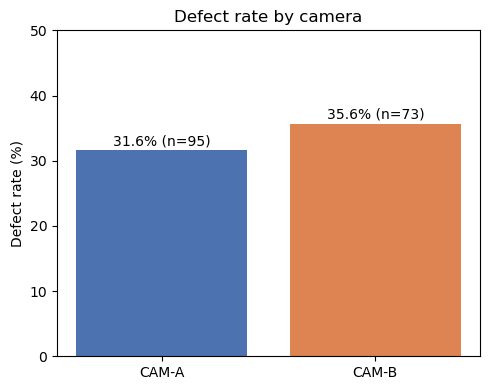

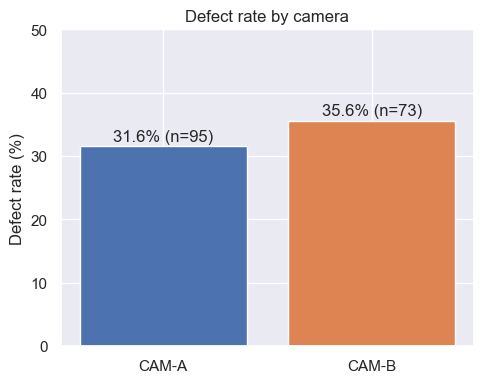

In [22]:
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(by_cam.index, by_cam["defect_rate"] * 100, color=["#4C72B0", "#DD8452"])
for bar, (_, r) in zip(bars, by_cam.iterrows()):
    label = f"{r['defect_rate']*100:.1f}% (n={int(r['n_images'])})"
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8, label, ha="center")
ax.set_ylabel("Defect rate (%)")
ax.set_title("Defect rate by camera")
ax.set_ylim(0, 50)
plt.tight_layout()
plt.show()

## 3. Chart and finding

In [23]:
# Defect rate for other splits, to see which factor matters
for col in ["shift", "exposure_setting"]:
    display(train.groupby(["camera", col])["inspector_label"]
            .agg(n_images="count", defect_rate="mean").round(3))

n_images  defect_rate
camera shift                       
CAM-A  DAY          46        0.283
       NIGHT        49        0.347
CAM-B  DAY          36        0.361
       NIGHT        37        0.351

n_images  defect_rate
camera exposure_setting                       
CAM-A  AUTO                    65        0.292
       NORMAL                  30        0.367
CAM-B  AUTO                    15        0.333
       LOW                     48        0.375
       NORMAL                  10        0.300

I checked day/night and the exposure setting for each camera. The differences are small and mostly stay between 25% and 40%, so neither one explains the defect rate well. The line is more interesting, so I look at it next.

## 3. Defect types by line

inspector_type,edge_chip,missing_hole,scratch,stain
line,,,,
LINE-1,4,4,9,12
LINE-2,10,5,4,8


inspector_type,edge_chip,missing_hole,scratch,stain
line,,,,
LINE-1,13.8,13.8,31.0,41.4
LINE-2,37.0,18.5,14.8,29.6


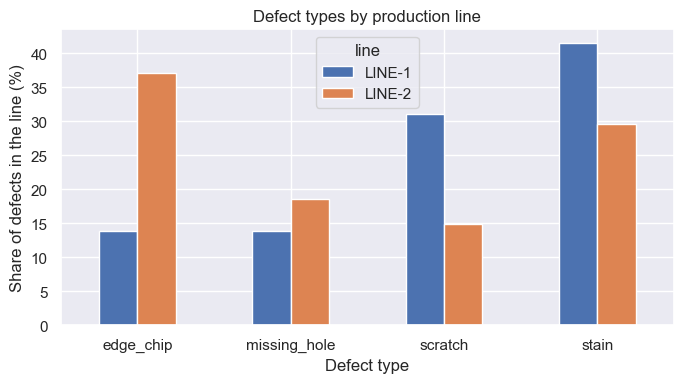

In [24]:
defective = train[train["inspector_label"] == 1]
types = pd.crosstab(defective["line"], defective["inspector_type"])
display(types)
types_pct = (types.div(types.sum(axis=1), axis=0) * 100).round(1)
display(types_pct)

ax = types_pct.T.plot(kind="bar", figsize=(7, 4), color=["#4C72B0", "#DD8452"])
ax.set_ylabel("Share of defects in the line (%)")
ax.set_xlabel("Defect type")
ax.set_title("Defect types by production line")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:** The lines have different kinds of defects. LINE-1 has mostly surface defects: stains and scratches are 21 of its 29 defects (72.4%), with 12 stains and 9 scratches. LINE-2 has about 2.5 times more edge chips (10 cases against 4 in LINE-1), and edge chips are 37.0% of the defects in LINE-2.

# Part B — Understanding the images

## B.1 Six sample images

Three images the inspector marked as **OK**, and three marked as **defective** — one of each defect type that appears in `train.csv` (`edge_chip`, `stain`, `scratch`).


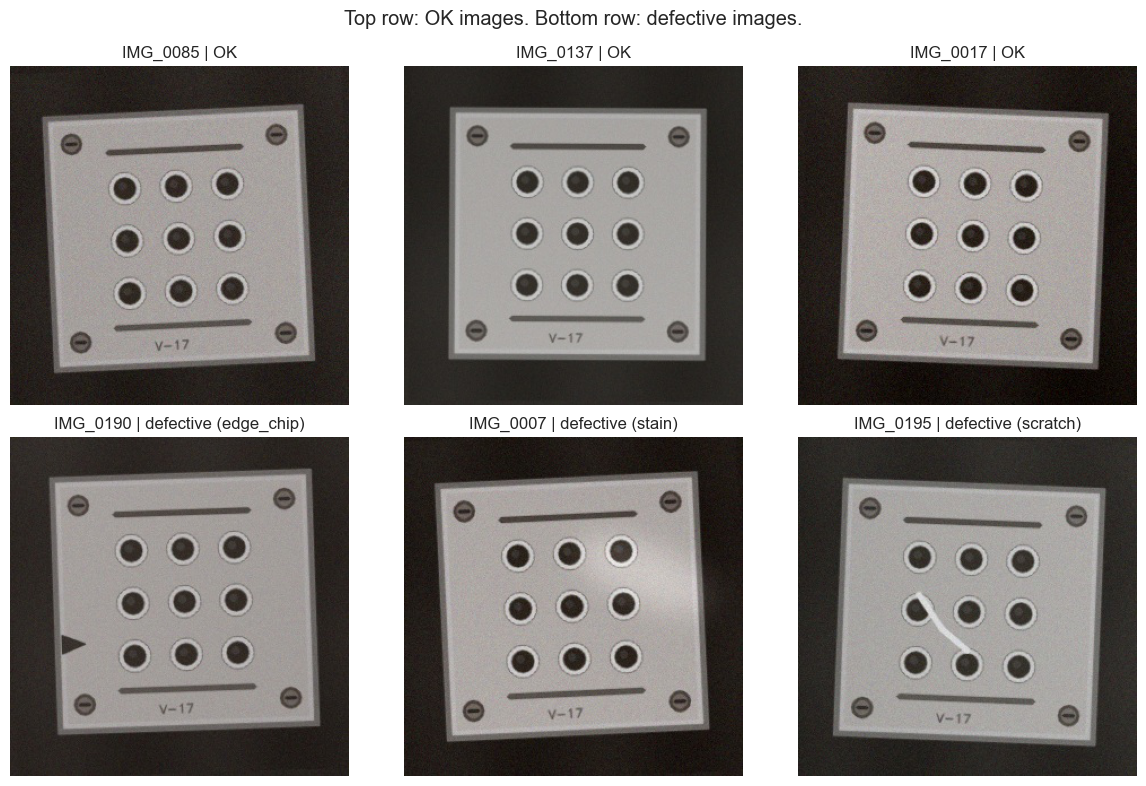

In [25]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path(".")
SEED = 42  # constant seed, so the same images are chosen every run
train = pd.read_csv(DATA_DIR / "train.csv")

# 3 OK images, and one defective image of each defect type
good = train[train["inspector_label"] == 0].sample(3, random_state=SEED)
bad = (train.set_index("image_id")
       .loc[["IMG_0190", "IMG_0007", "IMG_0195"]]  # edge_chip, stain, scratch
       .reset_index())
samples = pd.concat([good, bad])

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    ax.imshow(Image.open(DATA_DIR / row["file"]))
    status = "OK" if row["inspector_label"] == 0 else f"defective ({row['inspector_type']})"
    ax.set_title(f"{row['image_id']} | {status}")
    ax.axis("off")
fig.suptitle("Top row: OK images. Bottom row: defective images.")
plt.tight_layout()
plt.show()

### Main visual difference between normal and defective images

In normal images (inspector_label = 0), the component's surface is smooth and uniform, its outer edges are intact and symmetrical, and all mounting holes are clear and present, even when the component is rotated or when the overall image quality is poor (too dark, too bright, or blurry).
In contrast, defective images (inspector_label = 1) show a clear local change in texture or shape: a break in surface uniformity (a dark spot in stain or a sharp line in scratch), a damaged outer border (edge_chip), or a missing structural part (missing_hole).
Additionally, looking at the images by eye, we can see both False Positives and False Negatives in the data, meaning some normal components were labeled as defective, and some defective ones were labeled as normal.





## B.2 A function with two numeric features

Both features start from the same step: the image is read in greyscale and **normalised** to a fixed mean and standard deviation, so a dark photo and a bright photo of the same component look alike.

**1. `local_anomaly_score`** - local surface anomaly (top-hat + black-hat morphology).
Instead of looking at global brightness, I subtract the *local background*. A morphological top-hat keeps what is **brighter** than its close surroundings, and a black-hat keeps what is **darker**. A normal surface, even if it is dark or lit at an angle, changes smoothly, so both residuals stay near 0. A stain or a scratch is a sharp local jump relative to its neighbours, so it stands out. The score is the strongest residual divided by the image's typical residual level.

**2. `contour_complexity`** - geometric irregularity (perimeter relative to area).
Canny finds the boundary lines of the component, and the score is their total length divided by the square root of the component's area (from an Otsu mask). The measure does not care about rotation or weak lighting. An `edge_chip` makes the border jagged and longer, and a `missing_hole` removes a whole inner circle of edges - both change the ratio compared with a normal, symmetric component.


In [26]:
import math
import cv2
import numpy as np

KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))  # wider than a scratch
MARGIN = 10                                                     # skip the image border


def image_features(path):
    """Read one image and return two numeric features."""
    grey = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE).astype(np.float32)
    grey = (grey - grey.mean()) / (grey.std() + 1e-6) * 40 + 128   # normalise exposure

    # 1) local_anomaly_score: what is brighter (top-hat) or darker (black-hat)
    #    than its local background, smoothed so one noisy pixel cannot win
    tophat = cv2.morphologyEx(grey, cv2.MORPH_TOPHAT, KERNEL)
    blackhat = cv2.morphologyEx(grey, cv2.MORPH_BLACKHAT, KERNEL)
    residual = cv2.blur(np.maximum(tophat, blackhat), (3, 3))[MARGIN:-MARGIN, MARGIN:-MARGIN]
    local_anomaly_score = residual.max() / (residual.std() + 1e-6)

    # 2) contour_complexity: total length of the boundary lines / sqrt(component area)
    grey_u8 = np.clip(grey, 0, 255).astype(np.uint8)
    edges = cv2.Canny(cv2.GaussianBlur(grey_u8, (3, 3), 0), 50, 150)
    contours, _ = cv2.findContours(edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
    perimeter = sum(cv2.arcLength(c, False) for c in contours)
    _, mask = cv2.threshold(grey_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    area = max(cv2.countNonZero(mask), 1)
    contour_complexity = perimeter / math.sqrt(area)

    return {"local_anomaly_score": float(local_anomaly_score),
            "contour_complexity": float(contour_complexity)}


# check on the six images from B.1
check = pd.DataFrame([image_features(DATA_DIR / f) for f in samples["file"]],
                     index=samples["image_id"]).round(2)
check["label"] = samples["inspector_label"].values
check["type"] = samples["inspector_type"].values
check


,local_anomaly_score,contour_complexity,label,type
image_id,,,,
IMG_0085,7.72,30.49,0,none
IMG_0137,6.73,20.99,0,none
IMG_0017,7.68,29.49,0,none
IMG_0190,8.46,29.83,1,edge_chip
IMG_0007,7.35,29.53,1,stain
IMG_0195,8.57,31.78,1,scratch


## B.3 The features for all training images, and one comparison

I compute both features for the 168 training images and compare `local_anomaly_score` between the OK group and the defective group.


In [27]:
feats = pd.DataFrame([image_features(DATA_DIR / f) for f in train["file"]])
df = pd.concat([train, feats], axis=1)
print("rows:", len(df), "| missing values:", int(feats.isna().sum().sum()))

df.groupby("inspector_label")["local_anomaly_score"].agg(
    n="count", mean="mean", median="median", std="std",
    p90=lambda s: s.quantile(0.9)).round(2).rename(index={0: "0 - OK", 1: "1 - defective"})


rows: 168 | missing values: 0


,n,mean,median,std,p90
inspector_label,,,,,
0 - OK,112,7.14,7.08,0.52,7.94
1 - defective,56,7.73,7.52,1.16,9.26


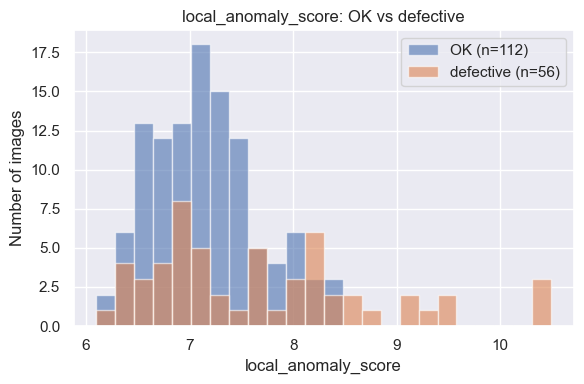

median by defect type:
inspector_type
edge_chip       7.53
missing_hole    6.69
none            7.08
scratch         9.19
stain           7.41


In [28]:
fig, ax = plt.subplots(figsize=(6, 4))
ok = df.loc[df["inspector_label"] == 0, "local_anomaly_score"]
bad = df.loc[df["inspector_label"] == 1, "local_anomaly_score"]
bins = np.linspace(df["local_anomaly_score"].min(), df["local_anomaly_score"].quantile(0.99), 25)
ax.hist(ok.clip(upper=bins[-1]), bins=bins, alpha=0.6, label=f"OK (n={len(ok)})", color="#4C72B0")
ax.hist(bad.clip(upper=bins[-1]), bins=bins, alpha=0.6, label=f"defective (n={len(bad)})", color="#DD8452")
ax.set_xlabel("local_anomaly_score")
ax.set_ylabel("Number of images")
ax.set_title("local_anomaly_score: OK vs defective")
ax.legend()
plt.tight_layout()
plt.show()

print("median by defect type:")
print(df.groupby("inspector_type")["local_anomaly_score"].median().round(2).to_string())


### Finding

- The OK images are packed tightly: median **7.08**, standard deviation 0.52, and none of them goes above 9.
- The defective images have a slightly higher centre (median 7.52) but, more importantly, a **long upper tail** (standard deviation 1.16, p90 9.26). **14.3%** of the defective images score above 9, against **0%** of the OK images - so a high score is a reliable signal, while a normal score says little.
- By defect type the score works as the theory says for **scratches** (median 9.19, the clear leader): a thin line is exactly the sharp local jump that top-hat / black-hat picks up. A `stain` (7.41) and an `edge_chip` (7.53) sit only a little above OK (7.08), and a `missing_hole` (6.69) is even lower - a hole that is *missing* is an absence of structure, not a bright or dark spot.
- Overall separation (AUC) is **0.64** for `local_anomaly_score` and **0.66** for `contour_complexity`. Neither is enough alone, but they react to different defect types, so combining them is more useful than either one.


# Part C - a first solution, and Part D - checking it

The features come from `features.py`, the same golden-template pipeline described in B.2: align each image onto a reference, compare it with the median of the clean images, and take two numbers from the difference map.

**How data leakage is avoided.** The split happens first. The reference image, the golden template, the scaler and the model are all built on the **development split only**. The validation images are used once, for the numbers in Part D. `test.csv` is only ever read to produce predictions - it never takes part in a fit, a threshold or a metric.


In [29]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from features import (Aligner, align_images, build_template, difference_map,
                      features_from_diff, load_grey, standardise, FEATURE_NAMES)

DATA_DIR = Path(".")
SEED = 42
sns.set_theme(style="whitegrid")

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train.shape, "| test:", test.shape, "| features:", FEATURE_NAMES)


train: (168, 10) | test: (72, 8) | features: ['max_diff_norm', 'area_norm']


## C.2 Development / validation split

A stratified 70/30 split keeps the same defect rate in both halves. Everything that follows is fitted on `dev` only.


In [30]:
dev, val = train_test_split(train, test_size=0.3, stratify=train["inspector_label"],
                            random_state=SEED)
print(f"dev {len(dev):>3} images, {int(dev.inspector_label.sum())} defective "
      f"({dev.inspector_label.mean():.1%})")
print(f"val {len(val):>3} images, {int(val.inspector_label.sum())} defective "
      f"({val.inspector_label.mean():.1%})")


dev 117 images, 39 defective (33.3%)
val  51 images, 17 defective (33.3%)


### The golden template, built from development OK images only

The reference image and the template both come from `dev`. The validation and test images are aligned onto that same reference so that they are comparable, but they contribute nothing to it.


In [31]:
dev_ok = dev.loc[dev["inspector_label"] == 0, "file"].tolist()
reference_file = dev_ok[0]

aligner = Aligner(standardise(load_grey(reference_file, DATA_DIR)))
aligned, failures = align_images(list(train["file"]) + list(test["file"]),
                                 reference_file, DATA_DIR, aligner)
print(f"aligned {len(aligned) - len(failures)} / {len(aligned)} images; failures: {failures}")

template = build_template(aligned[f] for f in dev_ok)
print(f"golden template built from {len(dev_ok)} dev OK images")


def feature_frame(frame):
    """Attach the two template features to a dataframe of images."""
    rows = [features_from_diff(difference_map(aligned[f], template)) for f in frame["file"]]
    return pd.concat([frame.reset_index(drop=True), pd.DataFrame(rows)], axis=1)


dev_f, val_f, test_f = feature_frame(dev), feature_frame(val), feature_frame(test)
dev_f.groupby("inspector_label")[FEATURE_NAMES].median().round(1)


aligned 240 / 240 images; failures: []
golden template built from 78 dev OK images


,max_diff_norm,area_norm
inspector_label,,
0,6.4,4.0
1,35.3,531.0


## C.1 The model

A logistic regression on the two features, inside a pipeline with a scaler so both features reach it on the same scale. `class_weight="balanced"` compensates for the 2:1 imbalance between OK and defective images.


In [32]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED),
)
model.fit(dev_f[FEATURE_NAMES], dev_f["inspector_label"])

print("coefficients:", dict(zip(FEATURE_NAMES, model[-1].coef_[0].round(3))))

dev_score = model.predict_proba(dev_f[FEATURE_NAMES])[:, 1]
val_score = model.predict_proba(val_f[FEATURE_NAMES])[:, 1]
val_pred = (val_score >= 0.5).astype(int)

print("dev AUC:", round(roc_auc_score(dev_f["inspector_label"], dev_score), 3),
      "| val AUC:", round(roc_auc_score(val_f["inspector_label"], val_score), 3))


coefficients: {'max_diff_norm': np.float64(1.798), 'area_norm': np.float64(-0.386)}
dev AUC: 0.869 | val AUC: 0.919


`max_diff_norm` gets a large positive weight: a strong local difference means a defect. `area_norm` gets a small **negative** weight - a difference spread over a wide area is usually alignment noise rather than a defect, so the model uses it to damp those cases.

## C.3 Predictions for `test.csv`

The same template, the same scaler, the same model - applied to the 72 test images. `score` is the model's probability for the defective class.


In [15]:
test_score = model.predict_proba(test_f[FEATURE_NAMES])[:, 1]
predictions = pd.DataFrame({
    "image_id": test_f["image_id"],
    "predicted_defect": (test_score >= 0.5).astype(int),
    "score": test_score.round(4),
})

assert len(predictions) == 72, f"expected 72 rows, got {len(predictions)}"
assert list(predictions.columns) == ["image_id", "predicted_defect", "score"]
assert set(predictions["image_id"]) == set(test["image_id"]), "image_id mismatch with test.csv"
assert predictions["predicted_defect"].isin([0, 1]).all()
assert predictions["score"].between(0, 1).all()
assert predictions.notna().all().all()
assert (predictions["predicted_defect"] == (predictions["score"] >= 0.5).astype(int)).all()

predictions.to_csv(DATA_DIR / "predictions.csv", index=False)
print(f"wrote predictions.csv: {len(predictions)} rows, "
      f"{int(predictions.predicted_defect.sum())} flagged "
      f"({predictions.predicted_defect.mean():.1%}); "
      f"train defect rate {train.inspector_label.mean():.1%}")
predictions.head()


wrote predictions.csv: 72 rows, 18 flagged (25.0%); train defect rate 33.3%


,image_id,predicted_defect,score
0,IMG_0001,0,0.1284
1,IMG_0002,0,0.2646
2,IMG_0003,0,0.3010
3,IMG_0010,0,0.3247
4,IMG_0014,1,0.9989


## D.1 Validation results

Confusion matrix, precision and recall - on the validation split only.


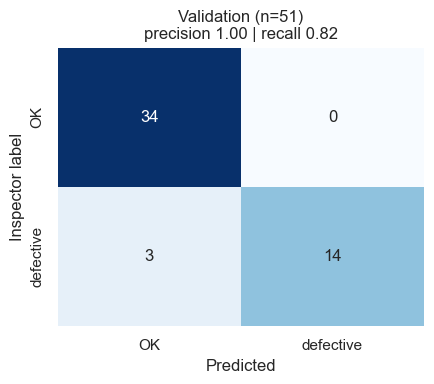

              precision    recall  f1-score   support

          OK       0.92      1.00      0.96        34
   defective       1.00      0.82      0.90        17

    accuracy                           0.94        51
   macro avg       0.96      0.91      0.93        51
weighted avg       0.95      0.94      0.94        51



In [16]:
cm = confusion_matrix(val_f["inspector_label"], val_pred)
precision = precision_score(val_f["inspector_label"], val_pred)
recall = recall_score(val_f["inspector_label"], val_pred)

fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["OK", "defective"], yticklabels=["OK", "defective"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Inspector label")
ax.set_title(f"Validation (n={len(val_f)})\nprecision {precision:.2f} | recall {recall:.2f}")
plt.tight_layout()
plt.show()

print(classification_report(val_f["inspector_label"], val_pred,
                            target_names=["OK", "defective"]))


## D.2 One image the solution got wrong

I list the validation errors and take the one the model was least sure about - the score closest to 0.5.


In [17]:
val_f = val_f.assign(score=val_score, predicted=val_pred)
errors = val_f[val_f["predicted"] != val_f["inspector_label"]].copy()
errors["uncertainty"] = (errors["score"] - 0.5).abs()
errors = errors.sort_values("uncertainty")

errors[["image_id", "inspector_label", "inspector_type", "predicted", "score"]
       + FEATURE_NAMES + ["camera", "exposure_setting"]].round(2)


,image_id,inspector_label,inspector_type,predicted,score,max_diff_norm,area_norm,camera,exposure_setting
49,IMG_0111,1,stain,0,0.31,15.48,2341,CAM-B,LOW
40,IMG_0039,1,stain,0,0.25,6.76,13,CAM-A,NORMAL
8,IMG_0025,1,stain,0,0.21,4.63,0,CAM-B,AUTO


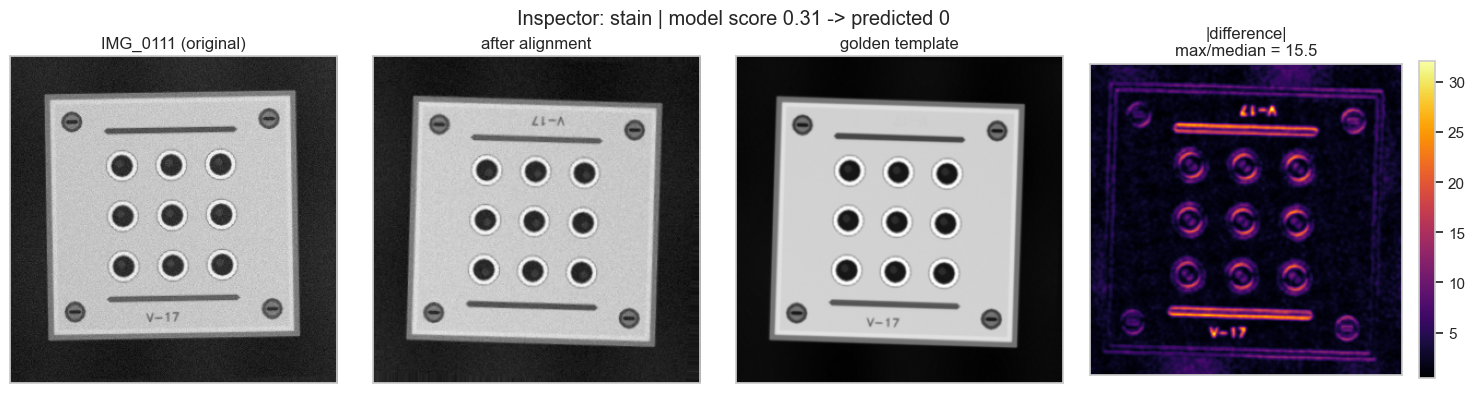

In [18]:
case = errors.iloc[0]
diff = difference_map(aligned[case["file"]], template)

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
axes[0].imshow(load_grey(case["file"], DATA_DIR), cmap="gray")
axes[0].set_title(f"{case['image_id']} (original)")
axes[1].imshow(aligned[case["file"]], cmap="gray")
axes[1].set_title("after alignment")
axes[2].imshow(template, cmap="gray")
axes[2].set_title("golden template")
im = axes[3].imshow(diff, cmap="inferno")
axes[3].set_title(f"|difference|\nmax/median = {case['max_diff_norm']:.1f}")
fig.colorbar(im, ax=axes[3], fraction=0.046)

for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Inspector: {case['inspector_type']} | model score {case['score']:.2f} "
             f"-> predicted {int(case['predicted'])}")
plt.tight_layout()
plt.show()


**Why the model missed it.**
The alignment step accidentally rotated the component by 180 degrees (notice the upside-down V-17 label in the "after alignment" image). Because the image was flipped, the difference map spread errors across the entire board, which caused the model's negative weight on area_norm to pull the defect score down to 0.31 (below the 0.5 threshold).